# Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, classification_report, precision_score, recall_score, confusion_matrix
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import lime
import lime.lime_tabular
import shap
shap.initjs()

The dataset set used in this project is a synthetic data generated for the purpose of this project using numpy. It reflect moniepoint customer transaction behaviour(Note: Not 100 % reflection). 
1. Total dataset: 1 million 
2. Sample data: 50 thousand
3. number of features: 27

In [4]:
# Load training data
data = "/Users/USER/Desktop/flexisaf/classification/data/raw/moniepoint.csv"
df = pd.read_csv(data)

# Print head()
df.head()

,Customer_type,Business,Region,State,Tier,Account_type,POS,Loan,Device,Occupation,...,Account_balance,Monthly_deposit,Monthly_withdrawal,POS_transaction,Recency,Login_frequency,Loan_amount,loan_repay_rate,Loan_repay_rate,Failed_txt_count
0,Individual,NaN,NorthEast,Gombe,tier 3,personal account,No,No,mobile app,IT Professional,...,1.999187e+01,1.000000e+03,5.443061e+02,2,113,50,0.0,0.0,0.0,8
1,Business,Pharmacy,SouthWest,Ekiti,tier 3,Business Account,No,No,mobile app,Business Owner,...,4.599053e+07,1.590765e+07,9.402412e+06,150,98,54,0.0,0.0,0.0,6
2,Business,Supermarket,SouthSouth,Rivers,tier 3,Business Account,Yes,No,pos,Business Owner,...,7.514539e+03,3.449232e+03,1.877913e+03,150,156,48,0.0,0.0,0.0,7
3,Individual,NaN,SouthWest,Ogun,tier 3,personal account,No,No,mobile app,Customer Representative,...,2.858398e+01,1.000000e+03,5.841393e+02,3,188,36,0.0,0.0,0.0,6
4,Individual,NaN,NorthEast,Borno,tier 3,personal account,No,No,mobile app,Government Official,...,3.816230e+01,1.000000e+03,7.068255e+02,1,81,60,0.0,0.0,0.0,5


In [5]:
# Sample 25_000 each from customer type (Business, Individual)
individual = df[df["Customer_type"]== "Individual"].sample(n = 25_000, random_state=42)
business = df[df["Customer_type"] == "Business"].sample(n= 25_000, random_state=42)

In [6]:
# Concatenate the two samples
df_customer = pd.concat([individual, business], axis = 0)

In [7]:
# Rset Index
df_customer.reset_index(inplace = True)

# Obtain valuable information about the data

In [8]:
# print information about the dataset

print("\n", "-" *100)
print("\n",df_customer.info())


print("\n", "-" *100)

# print the features
print("\nFeatures:",df_customer.columns)


print("\n", "-" *100)
# print the shape of the dataset
print("\nData Shape",df_customer.shape)


print("\n", "-" *100)
# print head of the dataset
print("\n",df_customer.head())




 ----------------------------------------------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               50000 non-null  int64  
 1   Customer_type       50000 non-null  str    
 2   Business            25000 non-null  str    
 3   Region              50000 non-null  str    
 4   State               50000 non-null  str    
 5   Tier                50000 non-null  str    
 6   Account_type        50000 non-null  str    
 7   POS                 50000 non-null  str    
 8   Loan                50000 non-null  str    
 9   Device              50000 non-null  str    
 10  Occupation          50000 non-null  str    
 11  Age                 50000 non-null  int64  
 12  Tenure              50000 non-null  int64  
 13  Monthly_txn_count   50000 non-null  int64  
 14  product_us

In [9]:
print("\n", "-" * 100)

# check for NAN values
print(df_customer.isna().sum())

print("\n", "-" * 100)
# check for duplicate values
print("\nNumber of duplicates", df_customer.duplicated().sum())


 ----------------------------------------------------------------------------------------------------
index                     0
Customer_type             0
Business              25000
Region                    0
State                     0
Tier                      0
Account_type              0
POS                       0
Loan                      0
Device                    0
Occupation                0
Age                       0
Tenure                    0
Monthly_txn_count         0
product_used              0
Total_txn_value           0
Avg_txn_valu              0
Avg_txn_value             0
Account_balance           0
Monthly_deposit           0
Monthly_withdrawal        0
POS_transaction           0
Recency                   0
Login_frequency           0
Loan_amount               0
loan_repay_rate           0
Loan_repay_rate           0
Failed_txt_count          0
dtype: int64

 --------------------------------------------------------------------------------------------------

# Drop redundant columns & NAN values

In [10]:
df_customer.drop(columns = ["index", "Avg_txn_valu", "loan_repay_rate", "Business"], inplace =True)

In [11]:
df_customer.head()

,Customer_type,Region,State,Tier,Account_type,POS,Loan,Device,Occupation,Age,...,Avg_txn_value,Account_balance,Monthly_deposit,Monthly_withdrawal,POS_transaction,Recency,Login_frequency,Loan_amount,Loan_repay_rate,Failed_txt_count
0,Individual,SouthWest,Oyo,tier 3,personal account,No,Yes,mobile app,Customer Representative,29,...,2062.6428,12.994570,1000.0,887.26025,3,180,33,1.000000e+07,0.467554,5
1,Individual,SouthEast,Ebonyi,tier 2,personal account,No,Yes,mobile app,Government Official,37,...,133450.6900,61.387270,1000.0,525.43010,0,239,4,2.207884e+06,0.289788,11
2,Individual,SouthSouth,Akwa Ibom,tier 3,personal account,No,Yes,mobile app,Banker,23,...,114725.1950,423.755860,1000.0,500.00000,0,276,11,2.619358e+04,0.340177,10
3,Individual,SouthEast,Enugu,tier 1,personal account,No,No,mobile app,Consultant,18,...,297185.8000,213.586060,1000.0,766.52875,0,256,4,0.000000e+00,0.000000,9
4,Individual,SouthSouth,Bayelsa,tier 2,personal account,No,No,mobile app,IT Professional,33,...,4190.5444,10.396873,1000.0,646.09530,1,218,26,0.000000e+00,0.000000,8


In [12]:
# df_customer.to_csv("bank_customer.csv", index = False)

# Exploratory Data Analysis

In [13]:
# Output descriptive statistic for numeric features from the dataset
numeric_features = ['Age', 'Tenure','Monthly_txn_count', 'product_used', 'Total_txn_value',
                     'Avg_txn_value', 'Account_balance', 'Monthly_deposit', 'Monthly_withdrawal',
                     'POS_transaction', 'Recency', 'Login_frequency', 'Loan_amount',
                     'Loan_repay_rate', 'Failed_txt_count']
print("\n",df_customer[numeric_features].describe())


                 Age       Tenure  Monthly_txn_count  product_used  \
count  50000.000000  50000.00000       50000.000000  50000.000000   
mean      39.821260     38.50624         103.717860      4.234880   
std       13.336581     24.28879          94.845792      1.224133   
min       18.000000      1.00000           1.000000      1.000000   
25%       30.000000     20.00000           9.000000      3.000000   
50%       39.000000     34.00000          19.000000      4.000000   
75%       49.000000     52.00000         200.000000      5.000000   
max       90.000000    120.00000         200.000000      8.000000   

       Total_txn_value  Avg_txn_value  Account_balance  Monthly_deposit  \
count     5.000000e+04   5.000000e+04     5.000000e+04     5.000000e+04   
mean      1.444148e+07   7.434569e+04     5.051597e+06     1.856611e+06   
std       1.932633e+07   2.359360e+05     1.547205e+07     5.267919e+06   
min       5.000000e+03   4.345909e+01     2.310168e+00     1.000000e+03   
2

In [14]:
# Reuseable function for plotting feature distribution

def plot_distribution(x, feature_name = "feature"):
    import warnings as wn
    wn.filterwarnings("ignore")
    # Basic descriptive statistic
    mean_val = x.mean()
    med_val = x.median()
    min_val = x.min()
    max_val = x.max()
    mod_val = x.mode()[0]
    std_val = x.std()

    # create figure
    fig, ax = plt.subplots(1, 2, figsize = (10, 4))
    
    # plot histogram
    ax[0].hist(x)
    ax[0].set_xlabel(f"{feature_name}")
    ax[0].set_ylabel("Frequency")

    # craete the axvline for the distribution descriptive statistics
    ax[0].axvline(x = mean_val, color = "orange", linestyle = "dashed", linewidth =2, label = "Mean")
    ax[0].axvline(x = med_val, color = "black", linestyle = "dashed", linewidth =2, label = "Median")
    ax[0].axvline(x = min_val, color = "gray", linestyle = "dashed", linewidth =2, label = "Min")
    ax[0].axvline(x = max_val, color = "gray", linestyle = "dashed", linewidth =2, label = "Max")
    ax[0].axvline(x = mod_val, color = "red", linestyle = "dashed", linewidth =2, label = "Mode")
    



    # create boxplot for each features
    ax[1].boxplot(x, vert = False)
    ax[1].set_xlabel(f"{feature_name}")
    
    

    
    fig.legend(loc = "upper right")
    fig.suptitle(f"\n{feature_name} Distribution")


    fig.show()

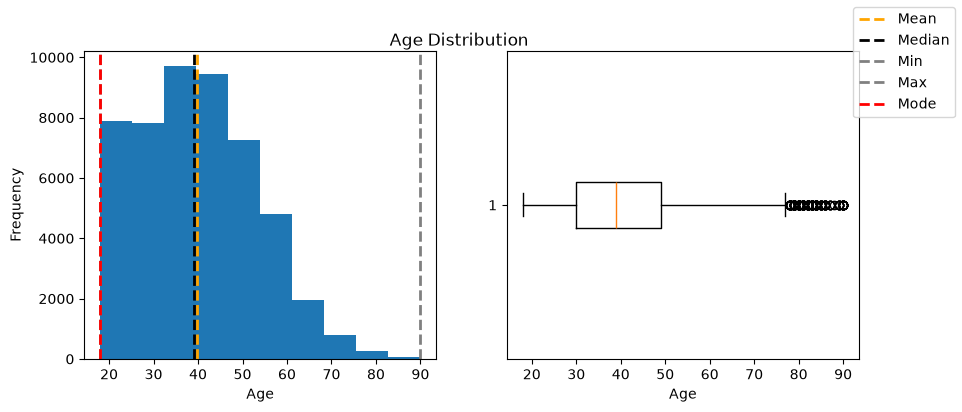

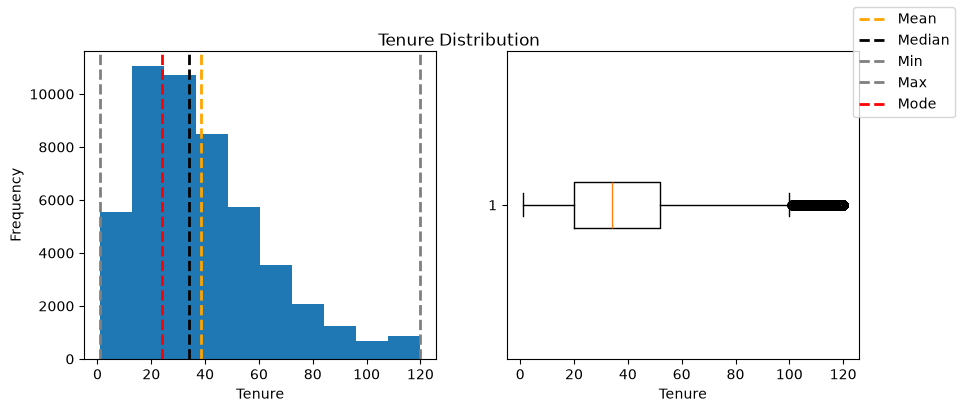

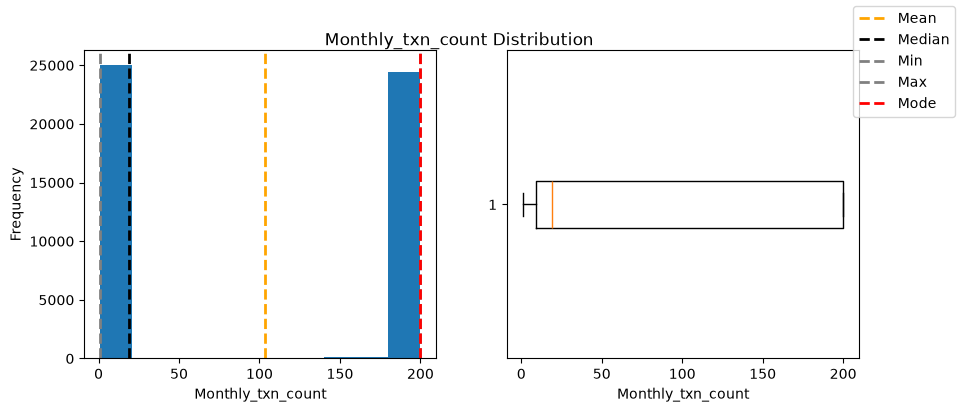

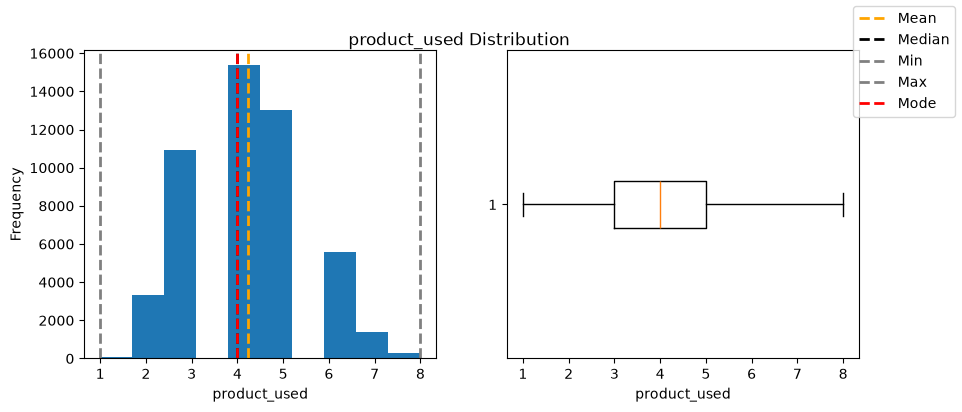

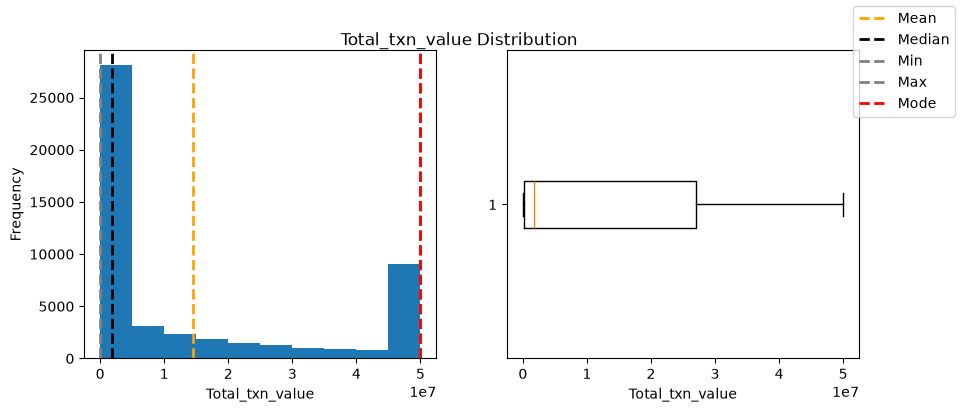

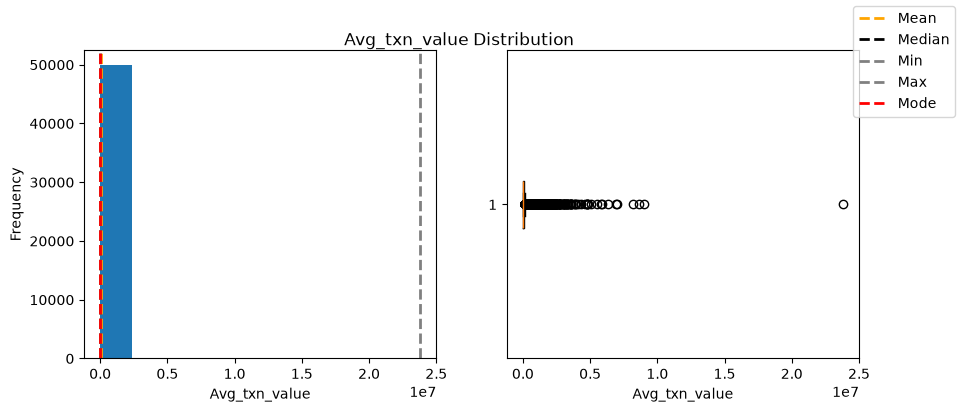

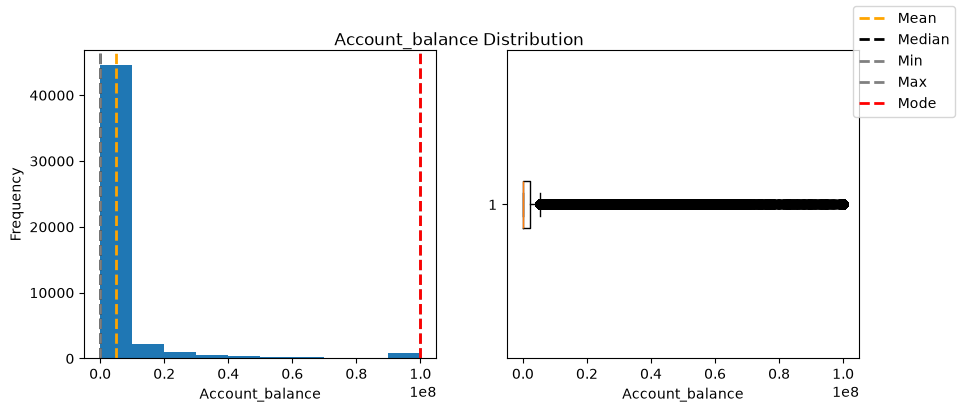

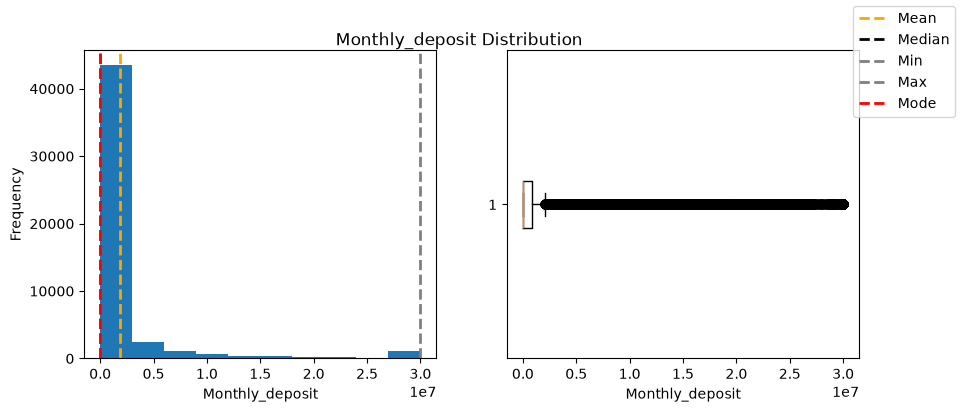

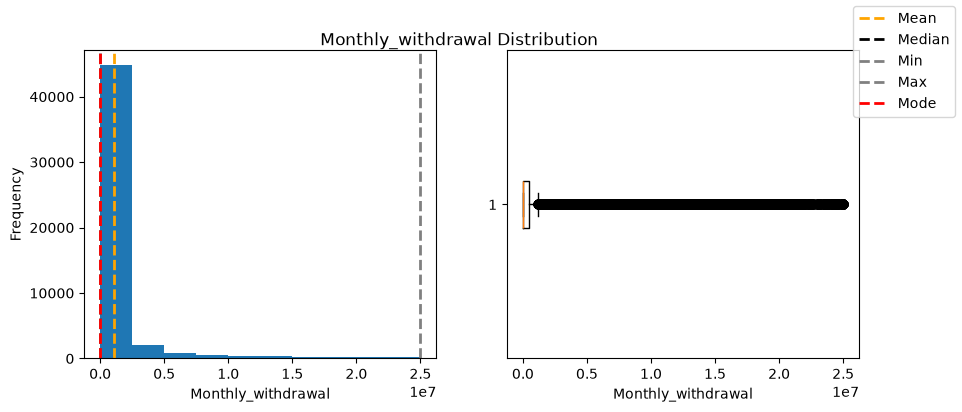

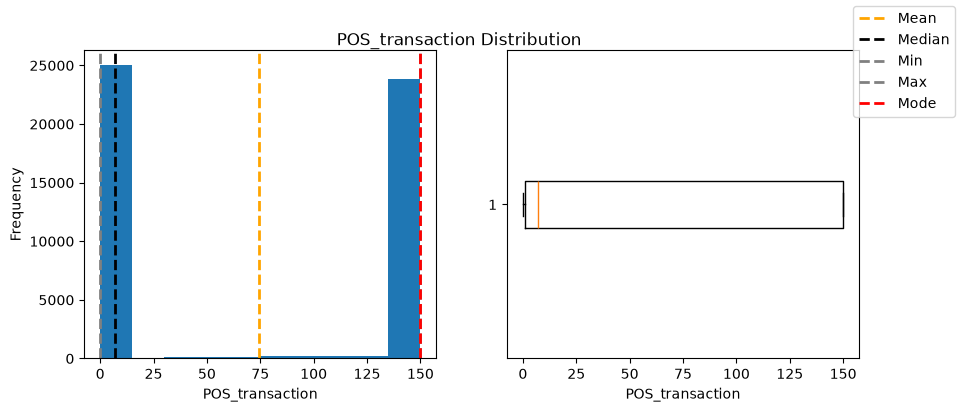

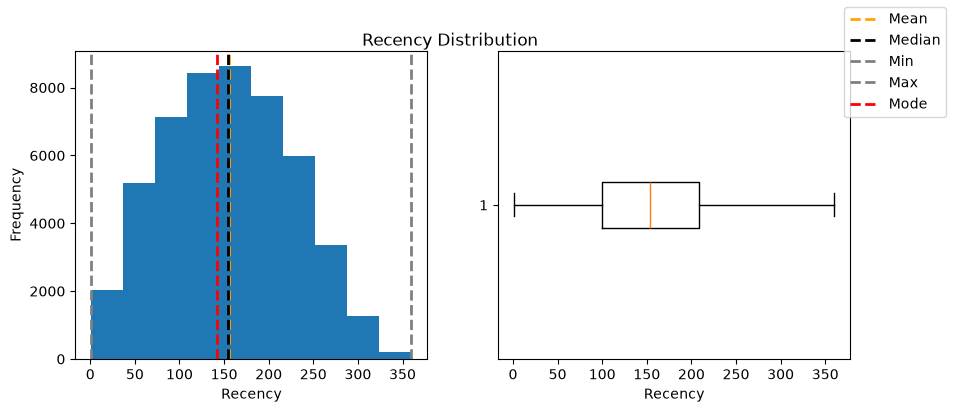

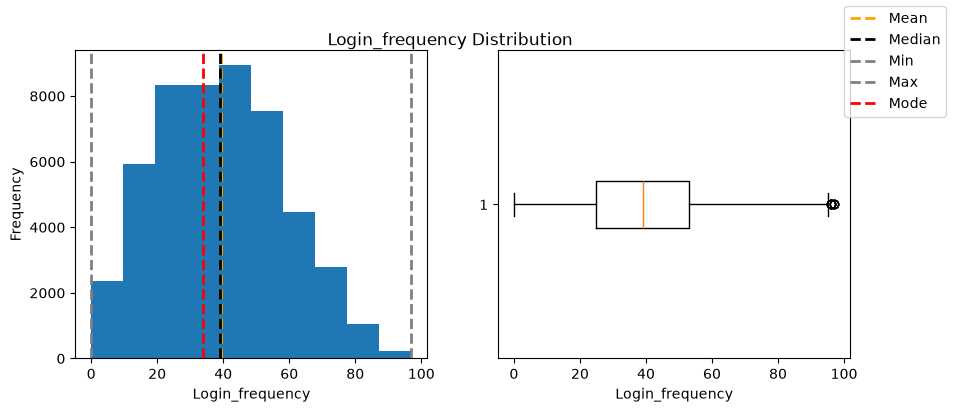

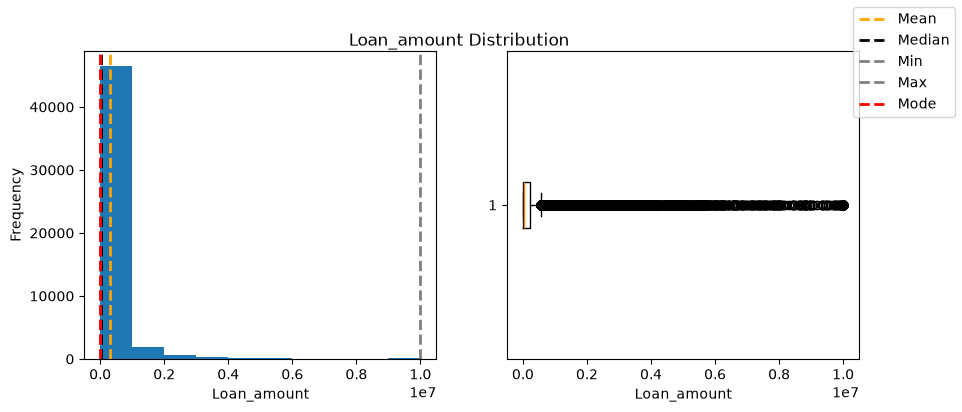

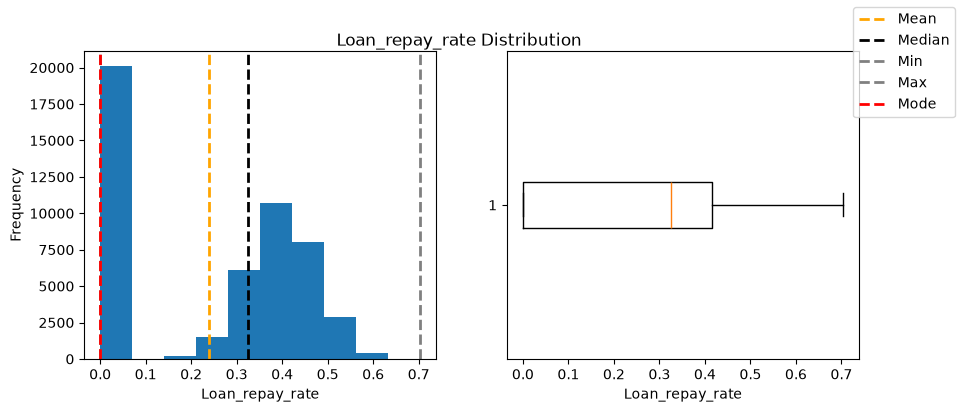

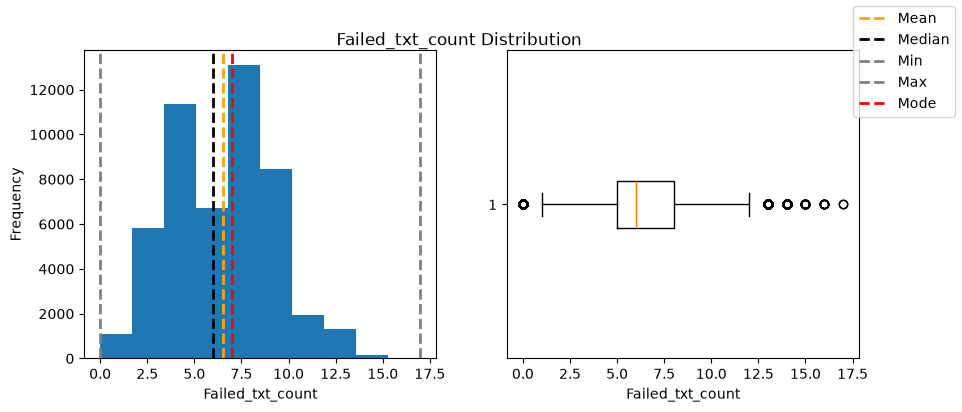

In [15]:
for col in numeric_features:
    plot_distribution(x = df_customer[col], feature_name = col)

In [16]:
category_feature = ['Customer_type', 'Region', 'State', 'Tier',
                    'Account_type', 'POS', 'Loan', 'Device', "Occupation"]

In [17]:
def plot_cat_distribution(data, x, feature_name = "feature", color = "orange"):
    

    for i in x:

    # create the figure
        fig, ax = plt.subplots(1, 2, figsize = (10, 4))


    # define categorical value counts

        cat_count = df[i].value_counts()

    # plot bar charts for categorical features

        ax[0].bar(cat_count.index, height = cat_count.values, color = color)
        ax[0].set_xlabel(f"{i}")
        ax[0].tick_params(rotation=90)

        ax[1].pie(cat_count)
        ax[1].legend(cat_count.keys().tolist())


        fig.suptitle(f"Data Distribution of {i} Feature")
    
        fig.show()  
    
    

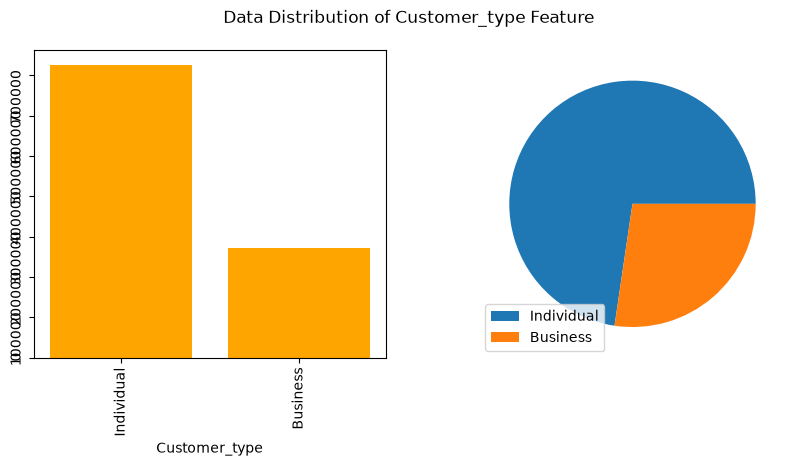

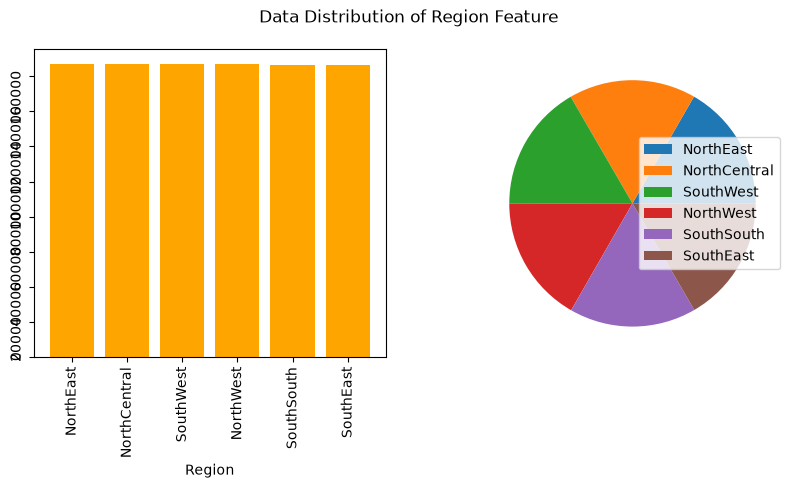

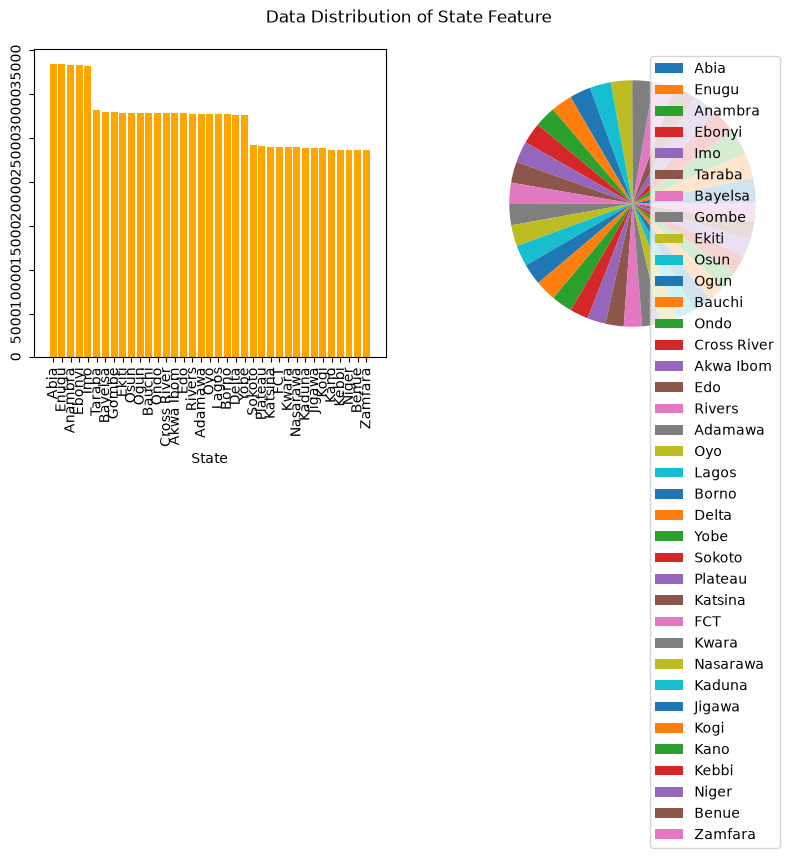

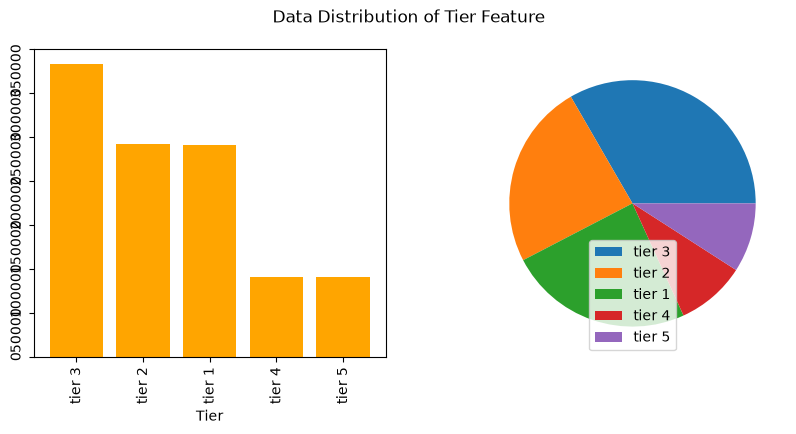

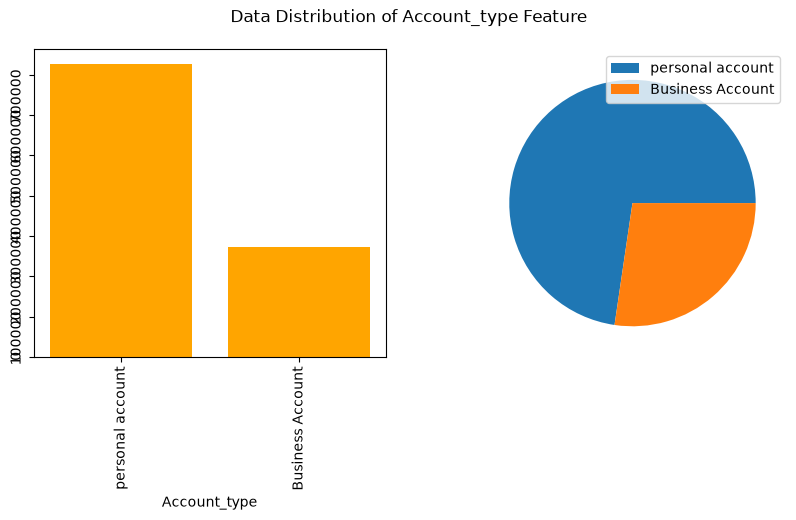

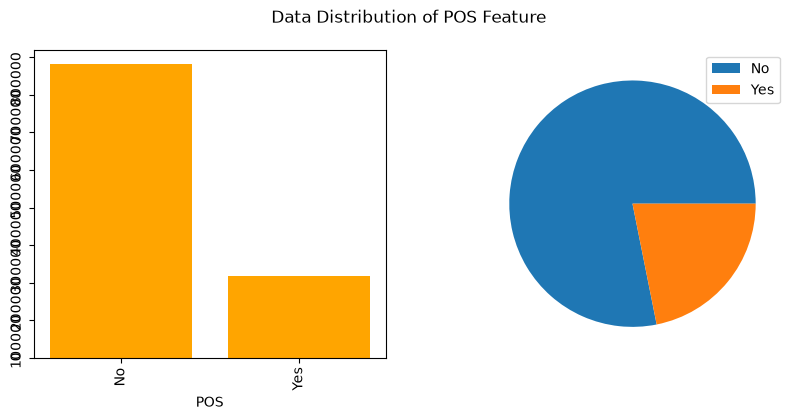

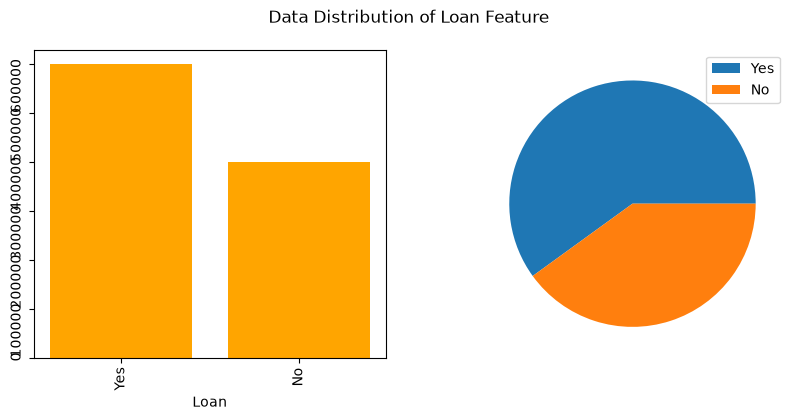

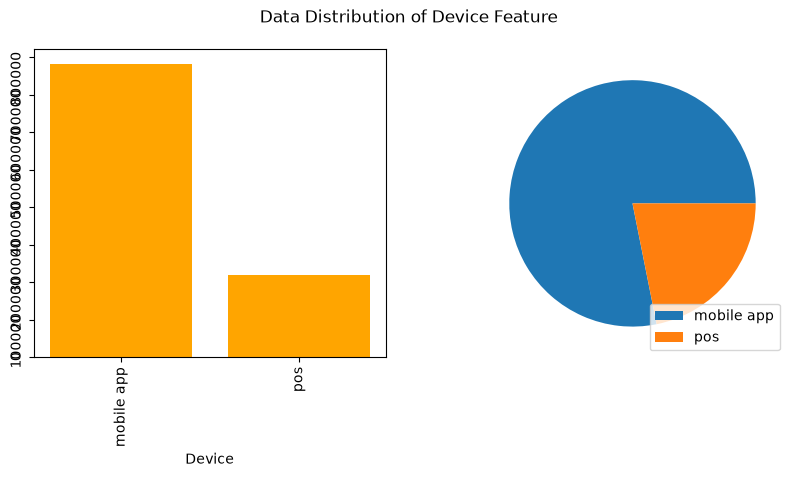

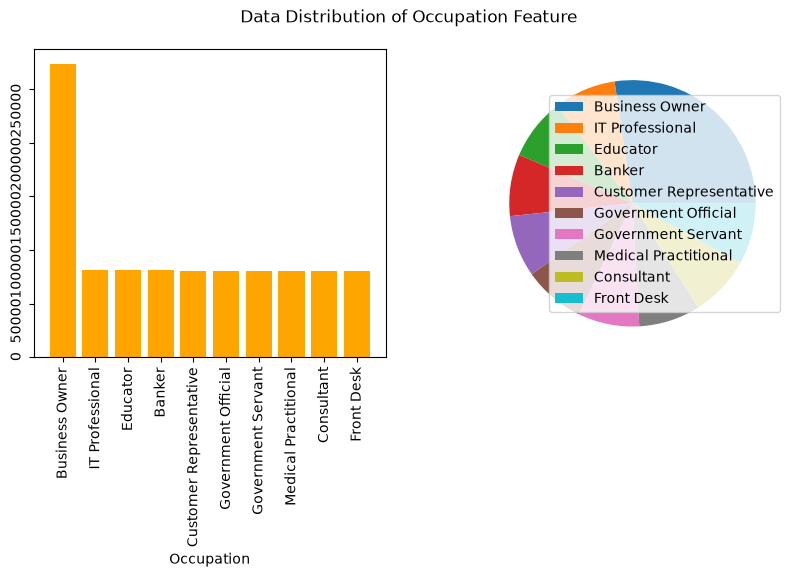

In [18]:
plot_cat_distribution(df_customer, x=category_feature)

In [19]:
# Drop redundant columns
df_customer.drop(columns = ["Occupation", "State", "Region"], inplace = True)

# Data Preprocessing

In [20]:
# separate the features by category
cat_features = ["Customer_type", 'Account_type', 'POS', 'Loan', 'Device']
hierchical_feature = ["Tier"]
num_features = ['Age', 'Tenure','Monthly_txn_count', 'product_used', 'Total_txn_value',
                     'Avg_txn_value', 'Account_balance', 'Monthly_deposit', 'Monthly_withdrawal',
                     'POS_transaction', 'Recency', 'Login_frequency', 'Loan_amount',
                     'Loan_repay_rate', 'Failed_txt_count']

In [21]:
# Create the proprocessor using ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ("tier", OrdinalEncoder(), hierchical_feature),
    ("num", StandardScaler(), num_features)
])

In [22]:
# Fit and transform the data
df_transformed = preprocessor.fit_transform(df_customer)

In [23]:
# Get feature names from the preprocessor
feature_names = preprocessor.get_feature_names_out()

In [24]:
# Convert transformed data into dataframe
df_customer_prep = pd.DataFrame(df_transformed, columns = feature_names, index = df_customer.index)

In [25]:
df_customer_prep

,cat__Customer_type_Business,cat__Customer_type_Individual,cat__Account_type_Business Account,cat__Account_type_personal account,cat__POS_No,cat__POS_Yes,cat__Loan_No,cat__Loan_Yes,cat__Device_mobile app,cat__Device_pos,...,num__Avg_txn_value,num__Account_balance,num__Monthly_deposit,num__Monthly_withdrawal,num__POS_transaction,num__Recency,num__Login_frequency,num__Loan_amount,num__Loan_repay_rate,num__Failed_txt_count
0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,...,-0.306370,-0.326501,-0.352251,-0.337019,-0.972174,0.348690,-0.336144,11.244914,1.120012,-0.567169
1,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.250515,-0.326498,-0.352251,-0.337129,-1.013055,1.173541,-1.864530,2.215697,0.250282,1.681807
2,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.171148,-0.326474,-0.352251,-0.337137,-1.013055,1.690820,-1.495609,-0.312365,0.496810,1.306977
3,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.944503,-0.326488,-0.352251,-0.337056,-1.013055,1.411210,-1.864530,-0.342717,-1.167526,0.932148
4,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,...,-0.297351,-0.326501,-0.352251,-0.337093,-0.999428,0.879950,-0.705065,-0.342717,-1.167526,0.557319
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,-0.255300,0.372920,0.585153,0.213963,1.030993,-1.203148,1.561163,3.103583,0.725979,-1.691657
49996,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.271694,-0.315369,-0.337870,-0.317599,1.030993,0.097041,-0.599659,-0.324223,0.767386,-0.192340
49997,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.216653,-0.024442,-0.018308,-0.079060,1.030993,-1.021401,0.717916,-0.158396,1.182040,-0.567169
49998,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,-0.248441,-0.300992,-0.325064,-0.319043,1.030993,-0.937518,0.928728,-0.104047,0.868899,-0.567169


FFor the transformed categorical features, i drop one of the cat_columns for each categorical variable, since 1 encoding for one indicate automatic 0 encoding for other.

In [26]:
df_customer_prep.drop(columns = ["cat__Customer_type_Individual", "cat__Account_type_personal account",
                                 "cat__POS_No", "cat__Loan_Yes", "cat__Device_pos"], inplace =True)
# Rename the feature names into the original feature name for consistency

df_customer_prep.columns = df_customer.columns


In [27]:
df_customer_prep.head()

,Customer_type,Tier,Account_type,POS,Loan,Device,Age,Tenure,Monthly_txn_count,product_used,...,Avg_txn_value,Account_balance,Monthly_deposit,Monthly_withdrawal,POS_transaction,Recency,Login_frequency,Loan_amount,Loan_repay_rate,Failed_txt_count
0,0.0,0.0,0.0,0.0,1.0,2.0,-0.811405,-1.255993,-0.998661,-1.008789,...,-0.306370,-0.326501,-0.352251,-0.337019,-0.972174,0.348690,-0.336144,11.244914,1.120012,-0.567169
1,0.0,0.0,0.0,0.0,1.0,1.0,-0.211545,1.337822,-1.083009,-1.008789,...,0.250515,-0.326498,-0.352251,-0.337129,-1.013055,1.173541,-1.864530,2.215697,0.250282,1.681807
2,0.0,0.0,0.0,0.0,1.0,2.0,-1.261300,-0.926619,-1.072466,-1.825702,...,0.171148,-0.326474,-0.352251,-0.337137,-1.013055,1.690820,-1.495609,-0.312365,0.496810,1.306977
3,0.0,0.0,0.0,1.0,1.0,0.0,-1.636212,0.185016,-1.083009,-1.008789,...,0.944503,-0.326488,-0.352251,-0.337056,-1.013055,1.411210,-1.864530,-0.342717,-1.167526,0.932148
4,0.0,0.0,0.0,1.0,1.0,1.0,-0.511475,-0.967791,-1.030292,-1.008789,...,-0.297351,-0.326501,-0.352251,-0.337093,-0.999428,0.879950,-0.705065,-0.342717,-1.167526,0.557319


In [28]:
# Define input feature x
X = df_customer_prep

# Clustering 

# -KMeans

In [29]:
km = KMeans(n_clusters =3, n_init = 10)

In [30]:
km_model = km.fit_transform(X)
print(km.labels_)

[1 1 1 ... 0 0 0]


In [31]:
sil_score = silhouette_score(X, km.labels_)
print(sil_score)

0.30484584325368336


# Test distinct k_clusters


Epoch: 1.....n_clusters = 2


WCSS: [653924.4068599227] |

Silhouette Score: [0.2884526236062621]|



Epoch: 2.....n_clusters = 3


WCSS: [653924.4068599227, 550737.393477855] |

Silhouette Score: [0.2884526236062621, 0.30484584325368336]|



Epoch: 3.....n_clusters = 4


WCSS: [653924.4068599227, 550737.393477855, 490970.4588919744] |

Silhouette Score: [0.2884526236062621, 0.30484584325368336, 0.22490967377810314]|



Epoch: 4.....n_clusters = 5


WCSS: [653924.4068599227, 550737.393477855, 490970.4588919744, 437332.4624512954] |

Silhouette Score: [0.2884526236062621, 0.30484584325368336, 0.22490967377810314, 0.21045125230020845]|



Epoch: 5.....n_clusters = 6


WCSS: [653924.4068599227, 550737.393477855, 490970.4588919744, 437332.4624512954, 410218.93410483206] |

Silhouette Score: [0.2884526236062621, 0.30484584325368336, 0.22490967377810314, 0.21045125230020845, 0.21549824314326427]|



Epoch: 6.....n_clusters = 7


WCSS: [653924.4068599227, 550737.393477855, 490970.4588919744,

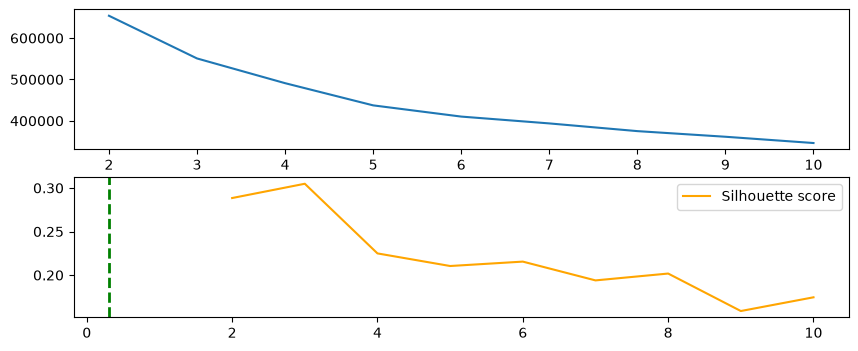

In [32]:
inertia = []
sil_score = []

for i in range(2, 11):
    km1= KMeans(n_clusters=i, n_init = 10)
    km1.fit_transform(X)
    inertia.append(km1.inertia_)
    sil_score.append(silhouette_score(X, km1.labels_))
    print(
        f"\nEpoch: {i-1}.....n_clusters = {i}\n"
        "\n===================================================================================================\n"
        f"\nWCSS: {inertia} |\n"
        f"\nSilhouette Score: {sil_score}|\n"
        "\n===================================================================================================\n")
fig, ax = plt.subplots(2, 1, figsize=(10,4))
ax[0].plot(range(2,11), inertia, label = "Inertia_s")
# Obtain maximum silhouette score
max_sil = np.max(sil_score)
ax[1].plot(range(2,11), sil_score, color = "orange", label = "Silhouette score")
ax[1].axvline(max_sil, linestyle = "dashed", color = "green", linewidth = 2)

plt.legend()
plt.show()

In [33]:
# Extract the labels and add to df_customer dataset(the unprocessed dataset)
label = km.labels_
df_customer["Label"] = label

# Exploratory Data Analysis(2) after Clustering

# Bivariate Analysis

In [34]:
def plot_scatter(data: pd.DataFrame, x, y, cust_type = None):
    # create figure
    for i in x:
        feat = data[i]
        correlation = feat.corr(data[y])
        plt.figure(figsize=(10,4))
        sns.scatterplot(data, x = y, y = i, hue = cust_type)
        plt.title(f"Relationship between numerical features and target <correlation coefficient: {correlation:.4f}>")
        plt.show()

In [35]:
def plot_boxplot(data, x, y, cust_type = None):
    # create figure
    for i in x:
        plt.figure(figsize=(10,4))
        sns.boxplot(data, x = y, y = i, hue = cust_type)
        plt.show()

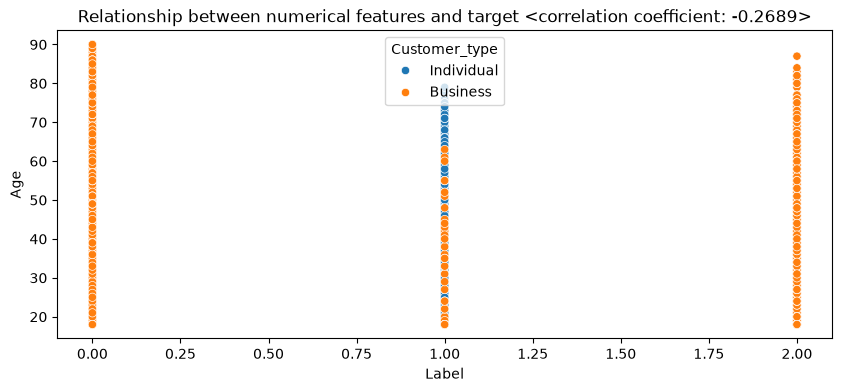

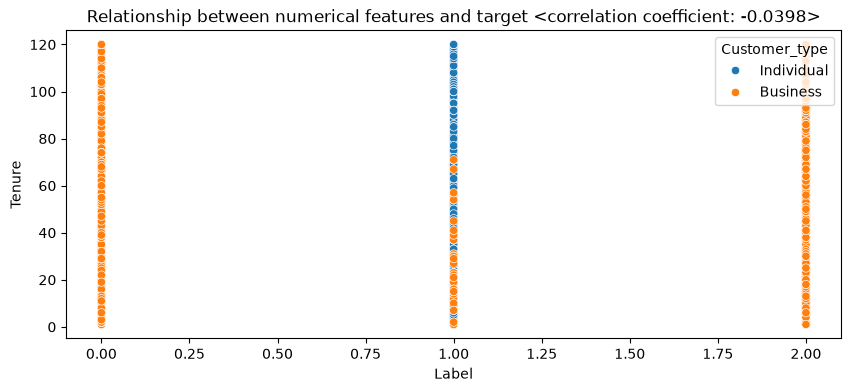

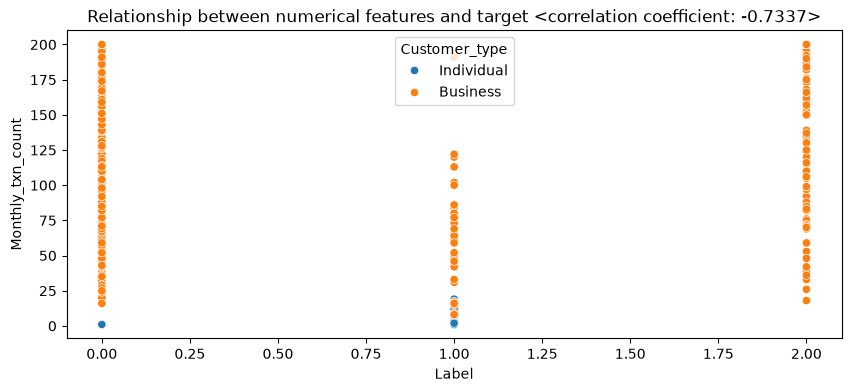

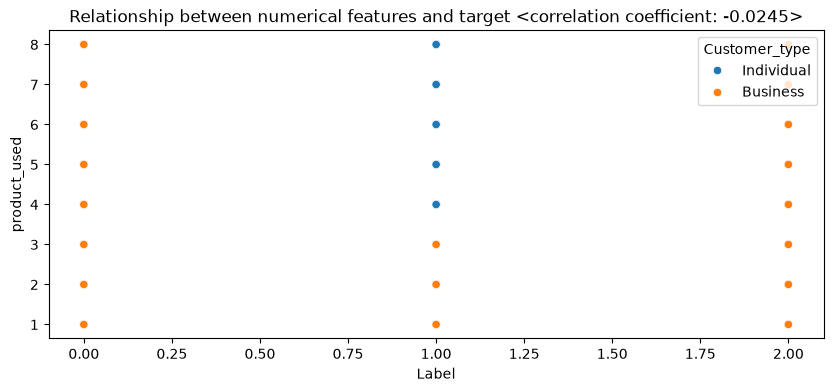

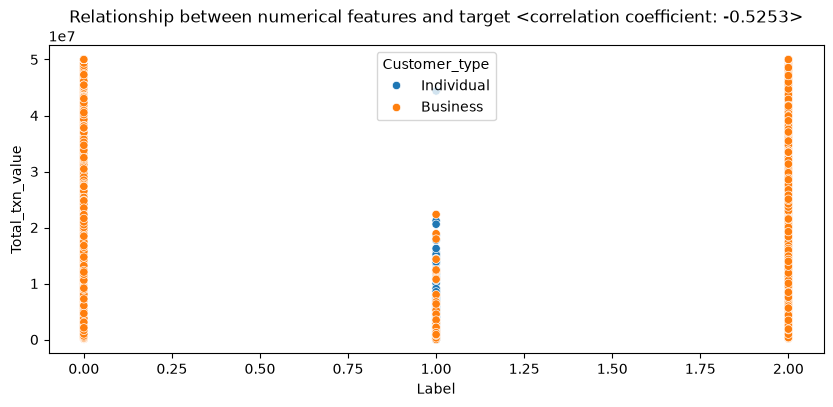

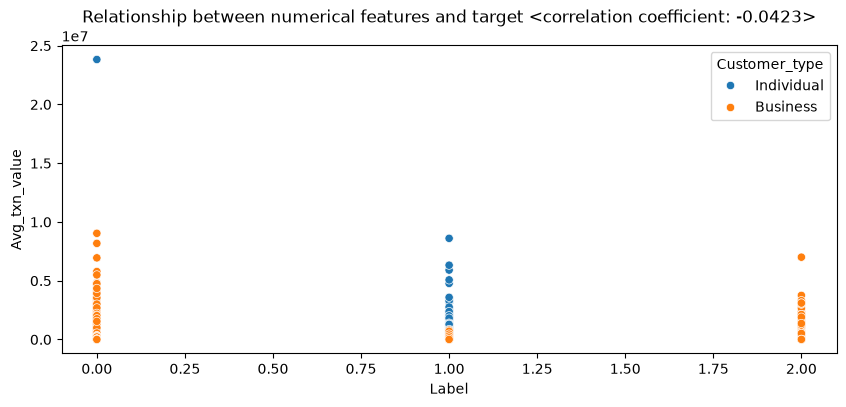

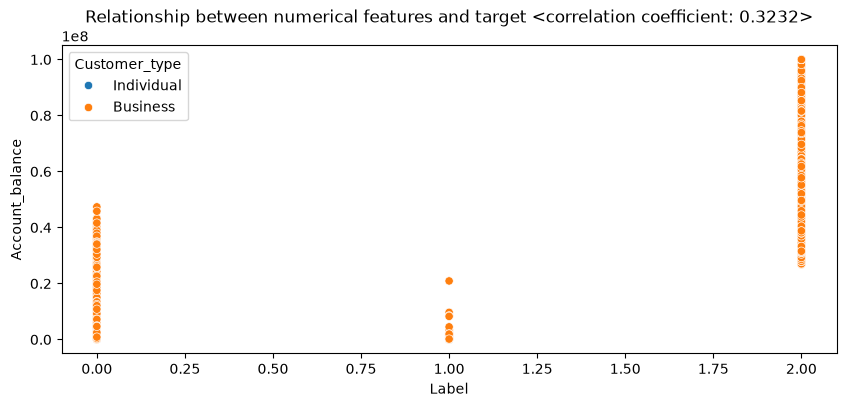

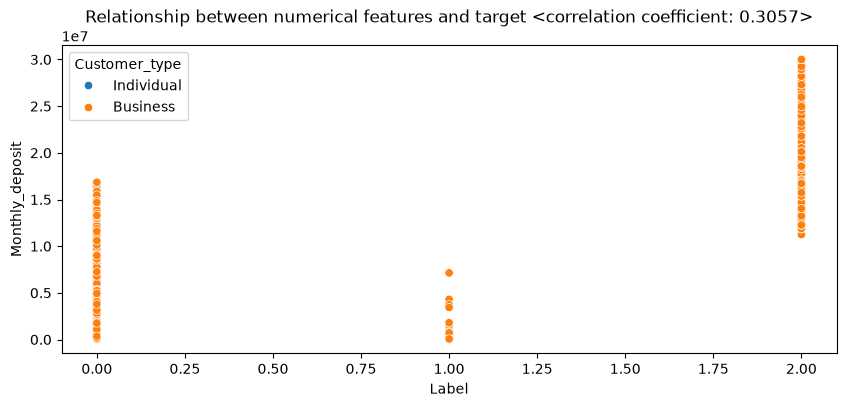

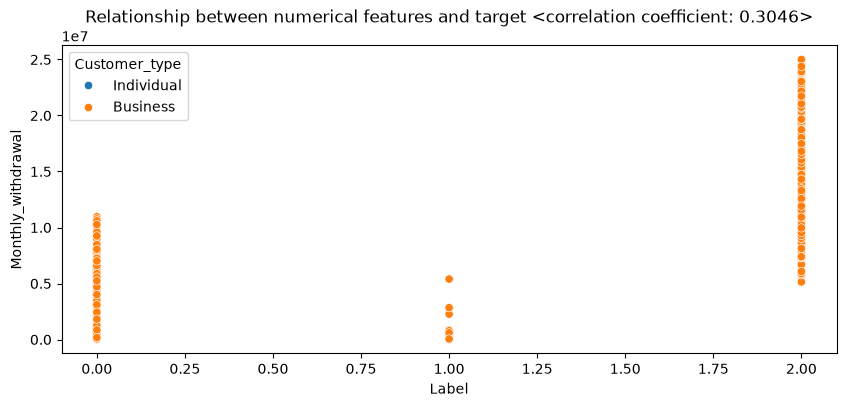

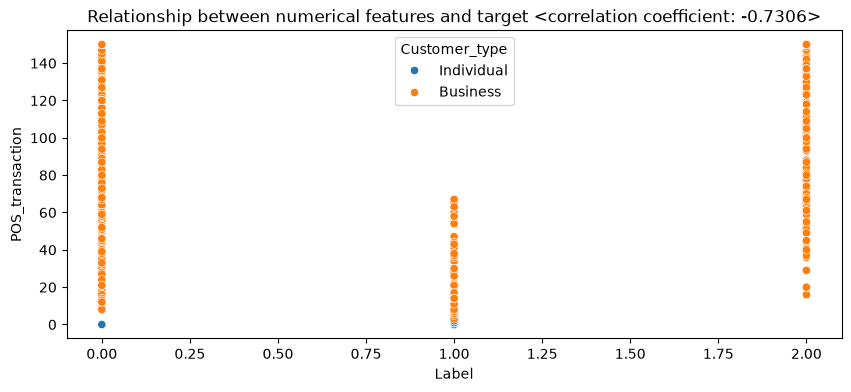

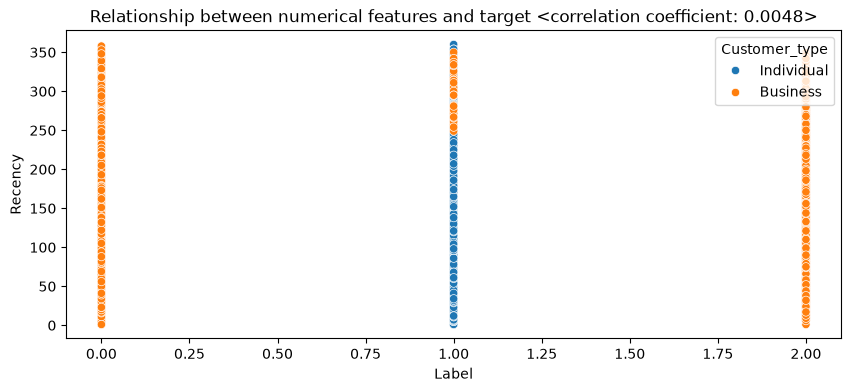

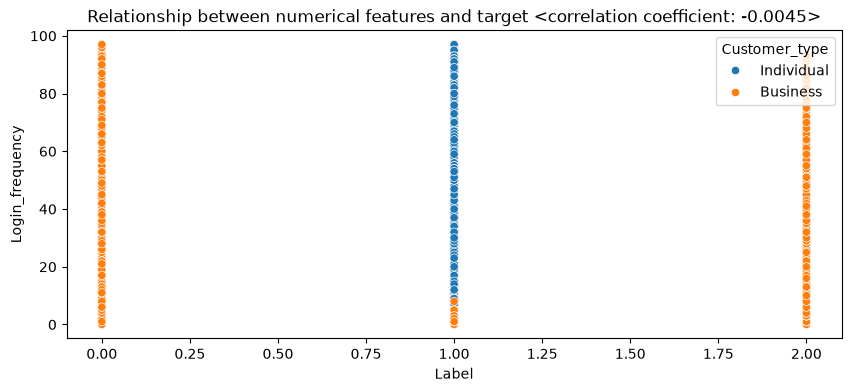

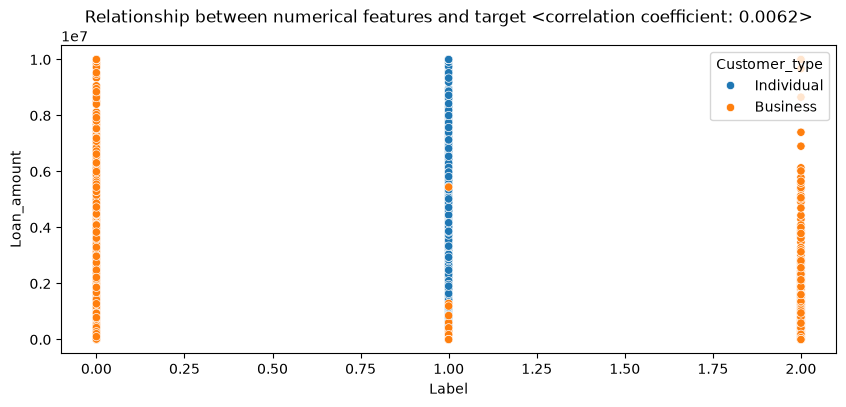

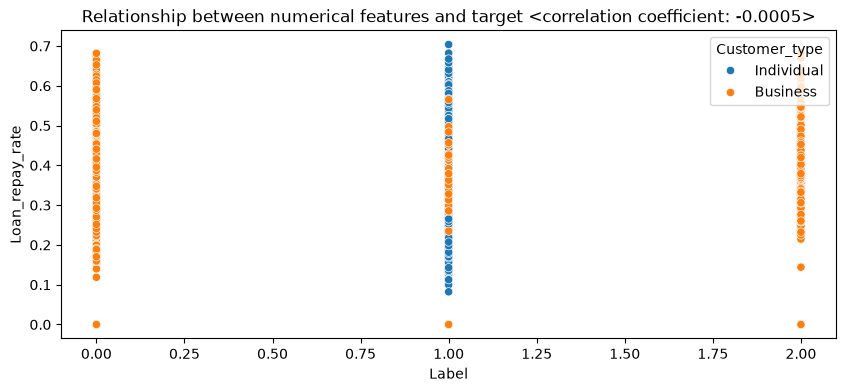

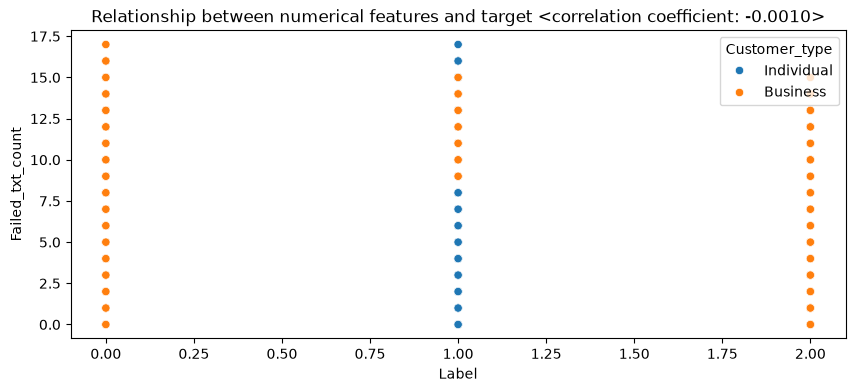

In [36]:
features = ['Age', 'Tenure','Monthly_txn_count', 'product_used', 'Total_txn_value',
            'Avg_txn_value', 'Account_balance', 'Monthly_deposit', 'Monthly_withdrawal',
            'POS_transaction', 'Recency', 'Login_frequency', 'Loan_amount',
            'Loan_repay_rate', 'Failed_txt_count']

plot_scatter(df_customer, features, "Label", cust_type = "Customer_type")

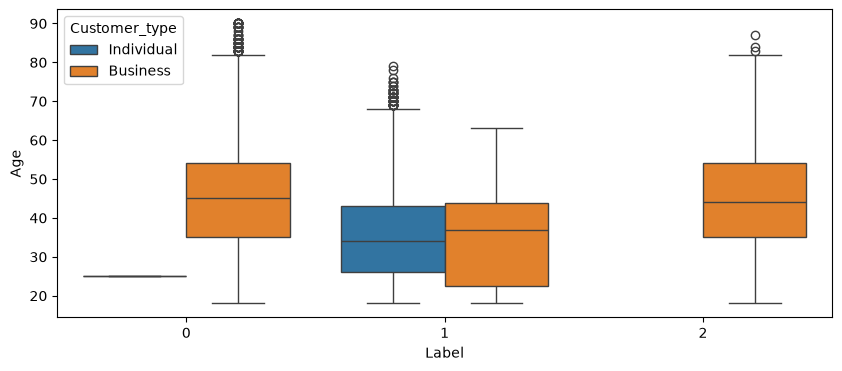

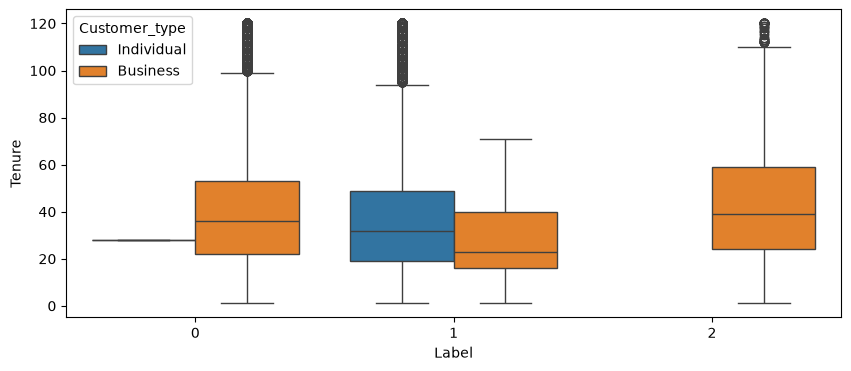

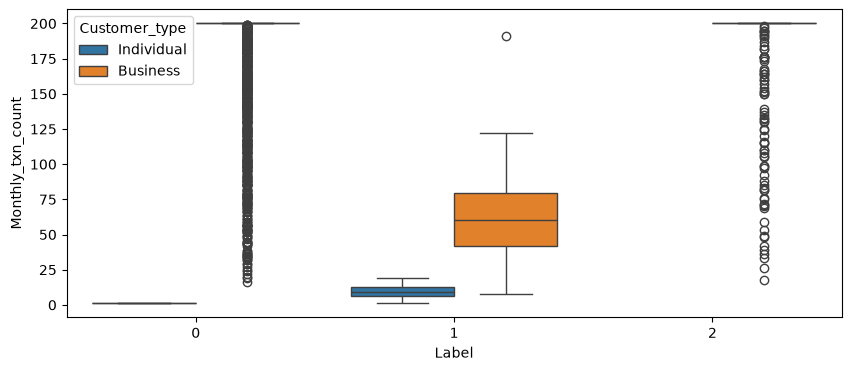

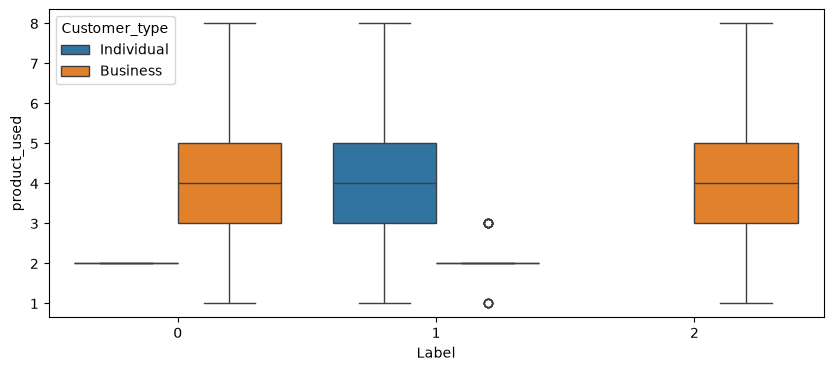

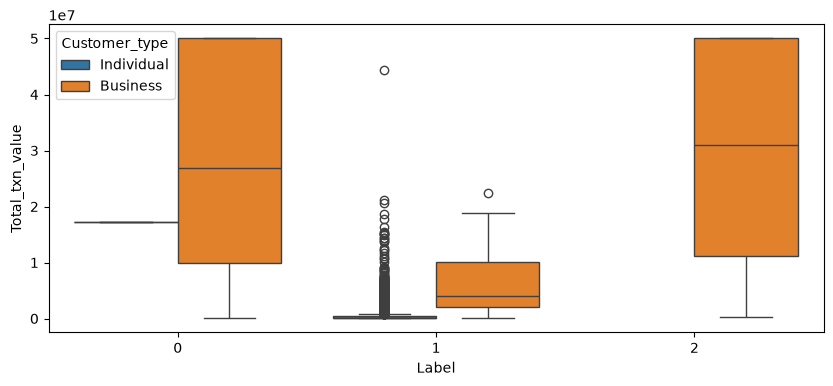

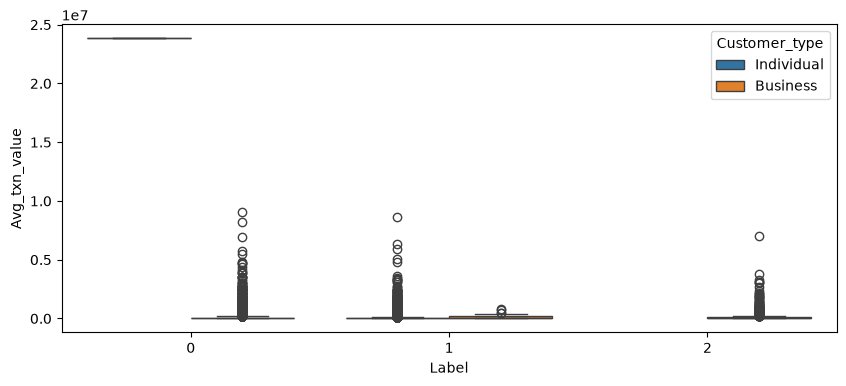

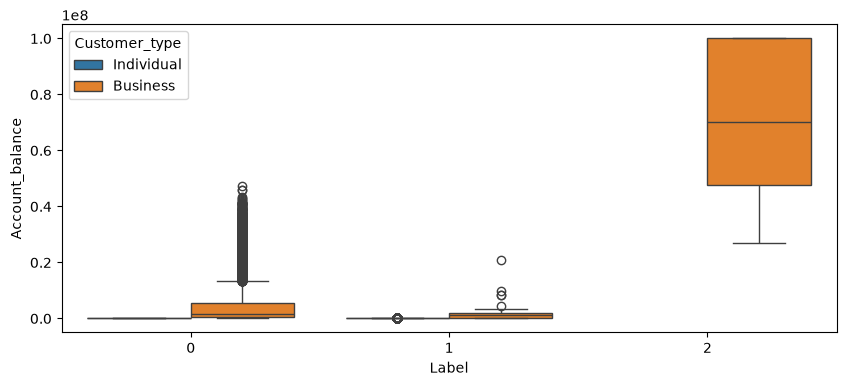

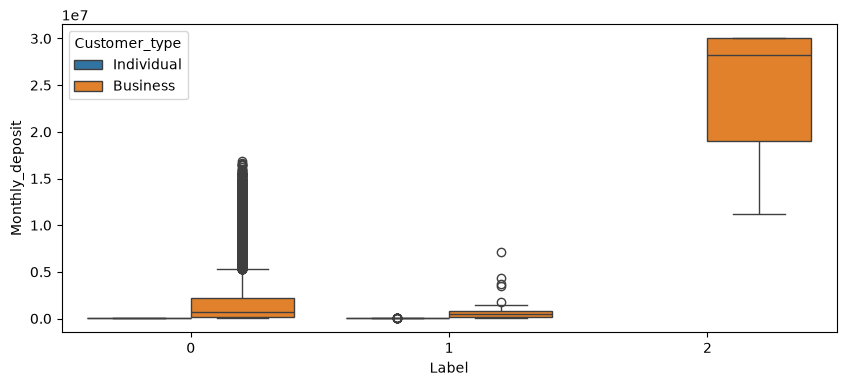

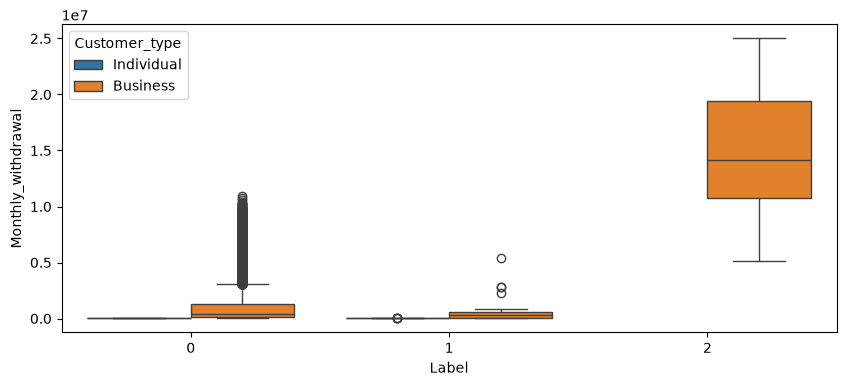

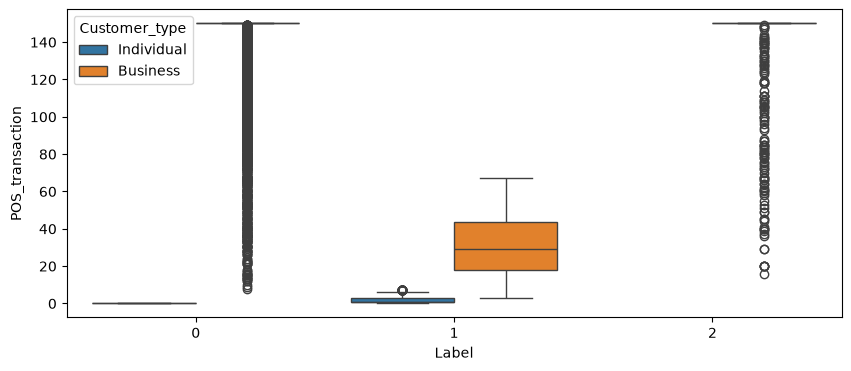

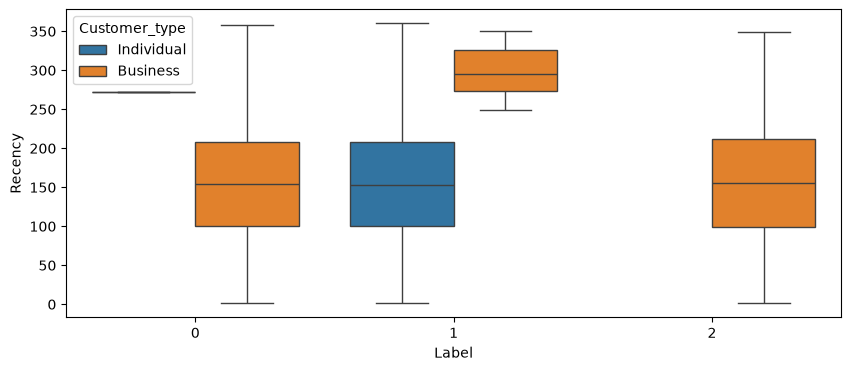

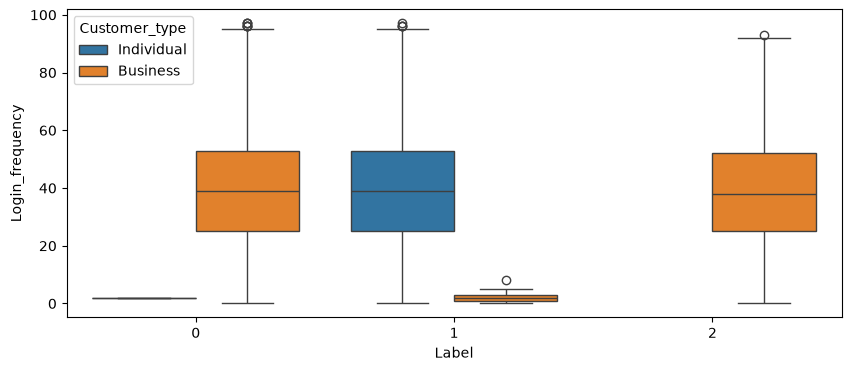

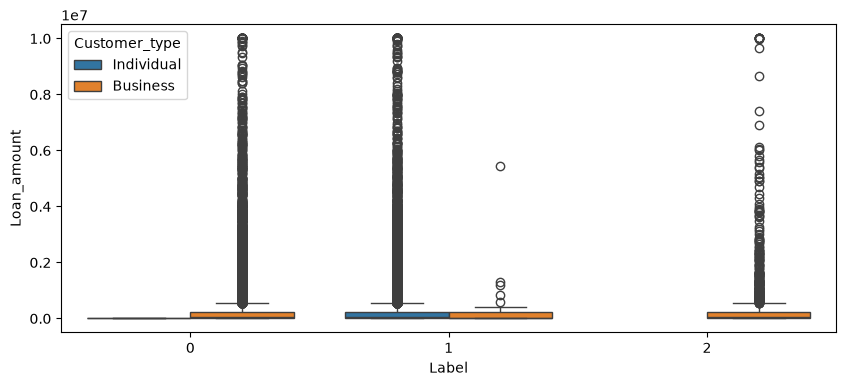

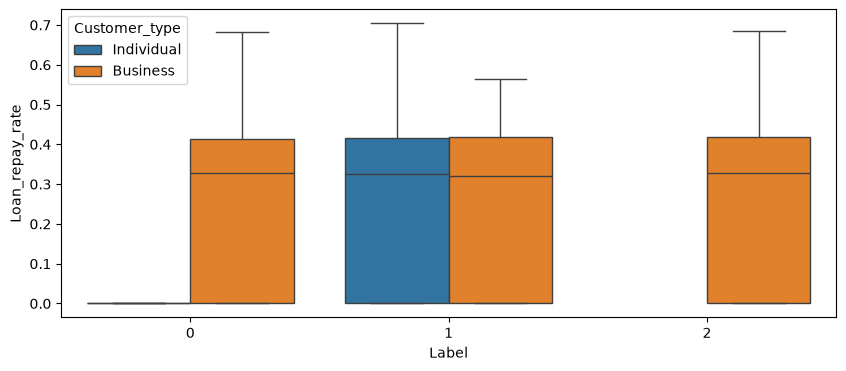

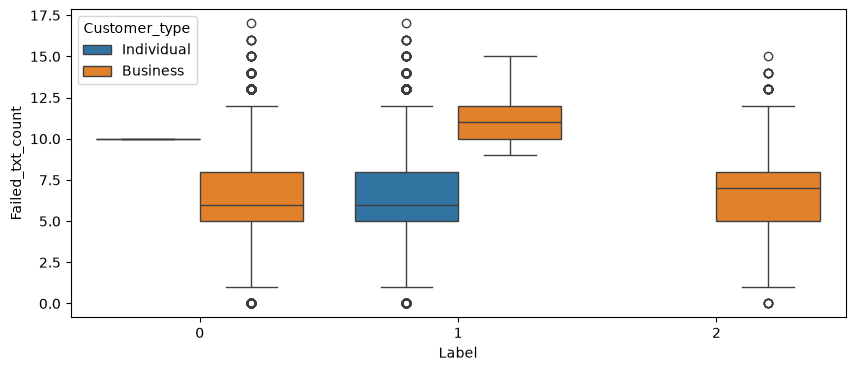

In [37]:
plot_boxplot(df_customer, features, "Label", cust_type = "Customer_type")

# Model training - MUltilayer Perceptron for customer segmentation

In [38]:
# define the X & y variable

X, y = df_customer.drop(columns = "Label"), df_customer["Label"]

In [39]:
# Split the X & y into training and validation set

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state = 42, stratify = y)

In [40]:
# Print shapes of training and validation data set
print(f"X_train: {X_train.shape}| X_test: {X_test.shape}| Y_train: {y_train.shape}| Y_test: {y_test.shape}")

X_train: (35000, 21)| X_test: (15000, 21)| Y_train: (35000,)| Y_test: (15000,)


# Model Training

In [41]:
# define the function with Pipeline containing the preprocessor and MLPClassifier 
mlp = Pipeline(steps =[
    ("preprocessor", preprocessor),
    ("model", MLPClassifier())]
)

In [42]:
# Train the model with training data
mlp_model = mlp.fit(X_train, y_train)

In [43]:
# Explore the model structure
mlp_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Customer_type','Tier','Account_type',...,'Loan_amount','Loan_repay_rate', 'Failed_txt_count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('tier', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying `

In [44]:
# Test trained model with validation dataset
prediction = mlp_model.predict(X_test)

In [45]:
# Evaluate prediction with classification report
report = classification_report(y_test, prediction)

In [46]:
# print the report
print(report)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6884
           1       1.00      1.00      1.00      7511
           2       0.99      0.99      0.99       605

    accuracy                           1.00     15000
   macro avg       1.00      1.00      1.00     15000
weighted avg       1.00      1.00      1.00     15000



In [47]:
# explore the matrix of confusion includong True positive, False positive, False negative & True negative
confusion = confusion_matrix(y_test, prediction)

<Axes: >

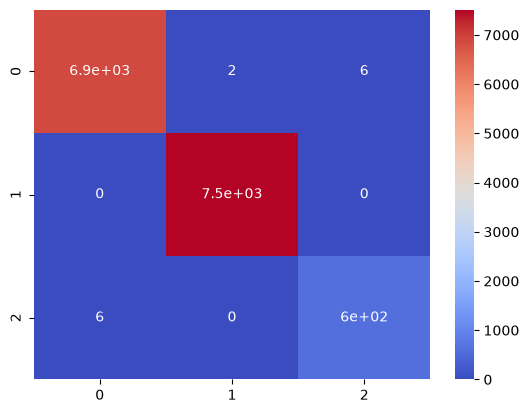

In [48]:
# visualise confusion matrix with seaborn heatmap
sns.heatmap(confusion, annot = True, cmap = "coolwarm")

In [49]:
# Save trained model with joblib

import joblib

filename = "./mlp_model"
joblib.dump(mlp_model, filename)

['./mlp_model']

# Test with Unseen Data

In [50]:
# load saved model
model = joblib.load(filename)

In [51]:
# An array of features for a customer transaction behavior
X_raw = np.array([
    ["Business","tier 5","Business Account","Yes","Yes","pos",15,1,1,1,200000,120445.99,100000.99,100000.99,100000.99,1,1,1,100000.99,1,0]
    
])
# convet to dataframe and use X_train feature names as the raw data feature names
X_ = pd.DataFrame(X_raw, columns = X_train.columns)
# Make prediction
predict = model.predict(X_)

In [52]:
print(predict)

[0]


In [53]:
# An array of features for multiple customer transaction behavior
X_raw = np.array([
    ["Business","tier 5","Business Account","Yes","No","mobile app",15,1,1,1,200000,120445.99,100000.99,100000.99,100020.99,1,12,1,100000.99,1,0],
    ["Individual","tier 1","personal account","Yes","Yes","pos",15,1,1,1,200000,120445.99,100000.99,100000.99,100000.99,1,2,2,10000420.99,1,34],
    ["Business","tier 2","Business Account","Yes","Yes","pos",15,1,1,1,200000,120445.99,100000.99,100000.99,100000.99,1,1,1,10035600.99,1,21],
    ["Business","tier 3","Business Account","Yes","Yes","pos",15,1,1,1,200000,120445.99,100000.99,100000.99,100000.99,1,1,1,30000.99,1,0],
    ["Individual","tier 4","personal account","Yes","Yes","pos",15,1,1,1,200000,120445.99,100000.99,100000.99,100000.99,1,1,1,60540000.99,1,0]
    
])
# convet to dataframe and use X_train feature names as the raw data feature names
X_ = pd.DataFrame(X_raw, columns = X_train.columns)
print(X_.shape)
# Make prediction
predict = model.predict(X_)

(5, 21)


In [54]:
print(predict)

[0 1 1 1 1]


In [55]:
# df_customer.to_csv("bank_customer(1).csv", index = False)

# Model Explanation with Shap explainer

In [60]:
mlp_ = model[-1]
prep = mlp_model.named_steps["preprocessor"]
mlp_

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",200
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None


In [61]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('tier', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_

In [71]:
# Preprocess training & Test Data for ExpanableAI
X_train_processed = prep.fit_transform(X_train)
feature_names = prep.get_feature_names_out()
print(feature_names)
train = pd.DataFrame(X_train_processed, columns = feature_names)

# Test data preprocess
X_test_processed = prep.fit_transform(X_test.sample(n = 1000, random_state=42))
test = pd.DataFrame(X_test_processed, columns = feature_names)

['cat__Customer_type_Business' 'cat__Customer_type_Individual'
 'cat__Account_type_Business Account' 'cat__Account_type_personal account'
 'cat__POS_No' 'cat__POS_Yes' 'cat__Loan_No' 'cat__Loan_Yes'
 'cat__Device_mobile app' 'cat__Device_pos' 'tier__Tier' 'num__Age'
 'num__Tenure' 'num__Monthly_txn_count' 'num__product_used'
 'num__Total_txn_value' 'num__Avg_txn_value' 'num__Account_balance'
 'num__Monthly_deposit' 'num__Monthly_withdrawal' 'num__POS_transaction'
 'num__Recency' 'num__Login_frequency' 'num__Loan_amount'
 'num__Loan_repay_rate' 'num__Failed_txt_count']


In [72]:
# define explainer
explainer = shap.Explainer(mlp_.predict_proba, train)

Background dataset has 35000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=35000 when initializing the masker.


In [88]:
shap_values = explainer(test)

PermutationExplainer explainer: 1001it [02:46,  5.66it/s]                          


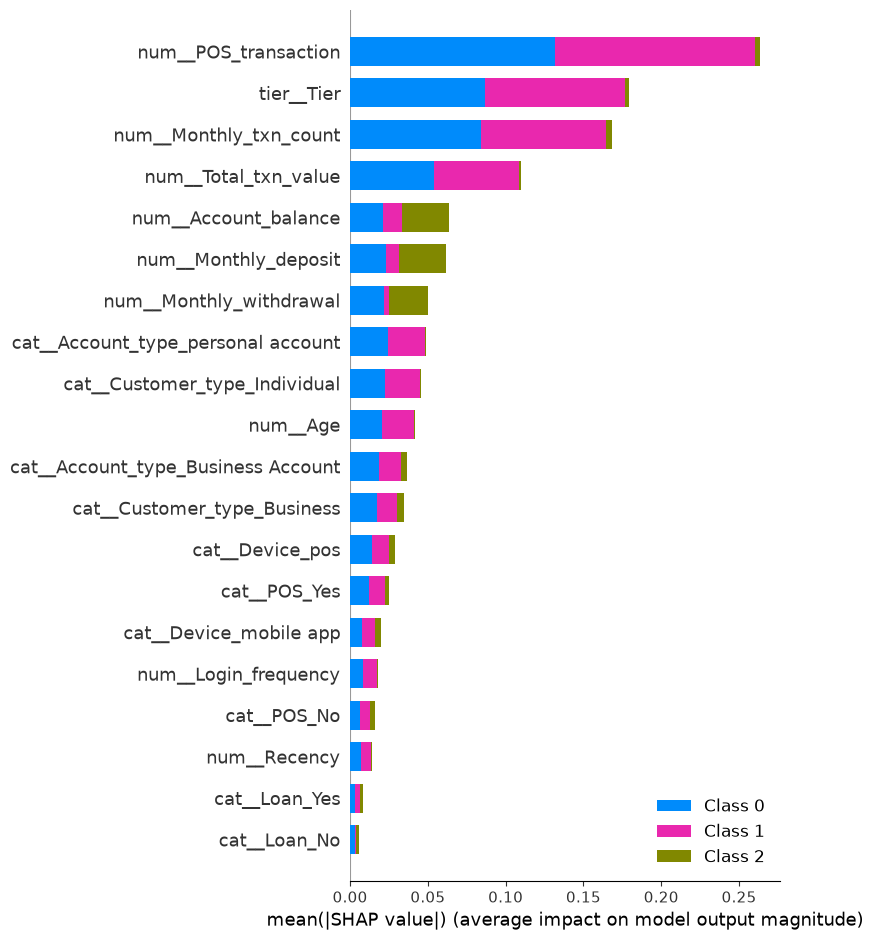

In [ ]:
# Global shap explainer of feature importance
shap.summary_plot(shap_values, test, plot_type = "bar")

In [ ]:
# force plot for explaining influence of features on segment 1 for customer with index 0

shap.plots.force(shap_values[0,:,1])

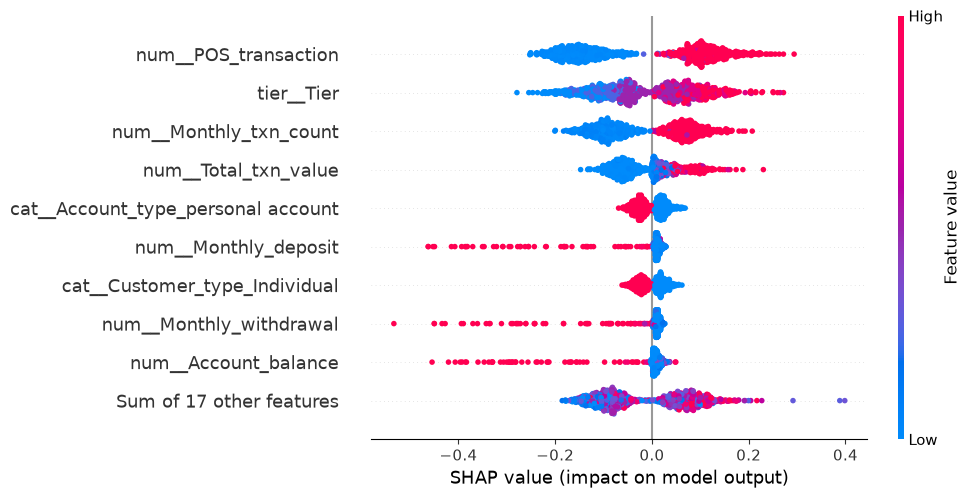

In [ ]:
# beeswarm plot for explaining influence of features on segment 0

shap.plots.beeswarm(shap_values[:,:,0])

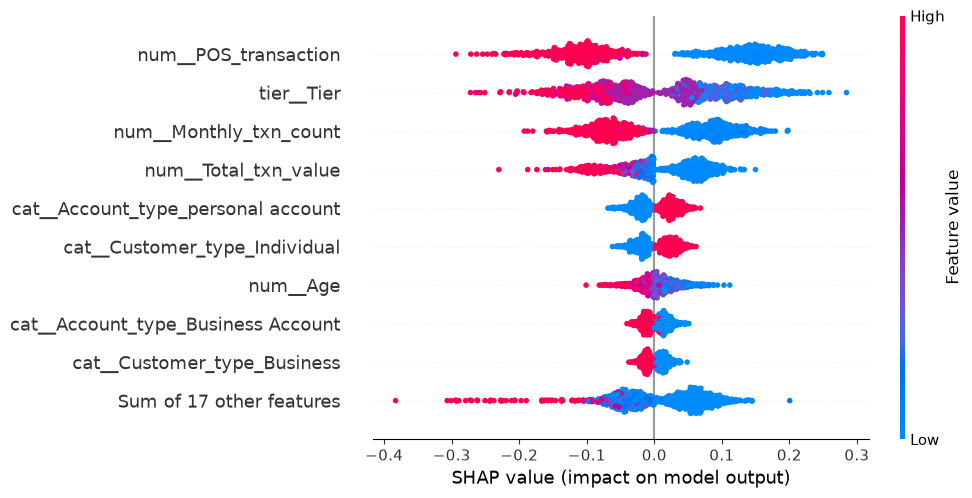

In [ ]:
# beeswarm plot for explaining influence of features on segment 1
shap.plots.beeswarm(shap_values[:,:,1])

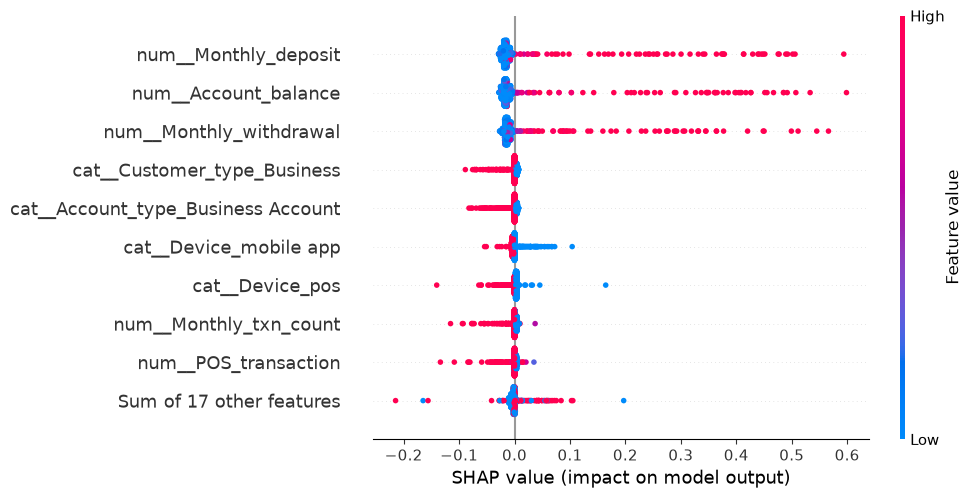

In [ ]:
# beeswarm plot for explaining influence of features on segment 2

shap.plots.beeswarm(shap_values[:,:,2])